# Buy the Weekend Dip?

**Does Bitcoin recover after a sharp hourly fall, and is the recovery stronger at weekends or when trading activity is low?**

This notebook goes through the project from raw data to backtest. Each section rebuilds its stage from the raw Binance files with the same code as the pipeline, and checks that every rebuilt table and figure is identical, byte for byte, to the saved result. Nothing is downloaded, no setting is changed, and no new run is saved. One primary historical held-out evaluation was accepted; rebuilding it here verifies that result without changing the saved evidence.

**Timeline (UTC):** raw data October 2019–July 2026; warm-up October–December 2019; development 2020–2023; historical held-out (pseudo-out-of-sample) 2024–July 2026. Market: Binance spot BTCUSDT, one-hour bars.

**Main finding:** the small weekend effect seen in development was never statistically different from zero, and it did not appear in the held-out period. None of the four confirmatory hypotheses H1–H4 was supported held out. The separate secondary H5 test did not establish shock asymmetry. All four primary strategies lost money held out under the primary cost assumption. All numbers below are computed by the code; none is typed in.

## How to run

Keep `notebook.ipynb` with the submitted `src/`, `config/`, `docs/`, `outputs/runs/`, dependency files and `data/` snapshot. From the project root, install `requirements-notebook.txt` into Python 3.12, select that environment as the kernel, then restart and run all cells. All paths are relative to the project root. A full run takes about two minutes, mostly for the 10,000-replicate bootstraps.

In [1]:
from pathlib import Path
import json
import platform

import pandas as pd
from IPython.display import Image, Markdown, display

from src.config import load_config
from src.validation import verify_acquisition_inputs
from src.features import verify_validation_input
from src.count_audit import verify_feature_input
from src.outcomes import verify_count_input, verify_development_inventory
from src.inference import verify_inference_inventory
from src.backtest import verify_backtest_inventory
from src.robustness import verify_inventory, verify_held_out_robustness_inventory
from src.heldout import verify_held_out_inventory
from src import replay
from src.replay import STAGE_REPLAYS, benchmark_bootstrap, benchmark_feature_steps

ROOT = Path.cwd().resolve()
if not (ROOT / 'config/project.yaml').is_file():
    raise RuntimeError('Run notebook.ipynb from the project root.')

cfg = load_config()
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 140)

RUNS = {
    'acquisition': Path('outputs/runs/20260904T112326.201050Z-acquire-61466e5a-95fc17'),
    'validation': Path('outputs/runs/20260904T150910.352311Z-validate-2114d1d3-82e4cb'),
    'features': Path('outputs/runs/20260906T003831.725064Z-features-92e5ff02-878985'),
    'counts': Path('outputs/runs/20260906T011026.732695Z-count-only-5b9fb859-11651d'),
    'outcomes': Path('outputs/runs/20260907T231307.800702Z-development-5b472caa-33cd7d'),
    'development_inference': Path('outputs/runs/20260908T152939.777879Z-development-0f73422e-0d444a'),
    'development_backtest': Path('outputs/runs/20260908T165150.697815Z-backtest-509b876c-aa730c'),
    'development_robustness': Path('outputs/runs/20260909T104454.475358Z-robustness-e052ad2d-dc18b3'),
    'held_out': Path('outputs/runs/20260910T133543.269946Z-held-out-dad36cad-632a5e'),
    'held_out_robustness': Path('outputs/runs/20260910T144404.535764Z-held-out-robustness-de2ac148-51637c'),
}

def read_csv(relative):
    return pd.read_csv(ROOT / relative)

def show_png(relative, width=900):
    display(Image(filename=str(ROOT / relative), width=width))

replays = []
replayed_stages = []

def check_replay(stage_replay):
    """Rebuild one stage and stop if any file differs from the saved run."""
    result = stage_replay(cfg)
    different = [item.name for item in result.comparisons if not item.matches]
    if different or not result.matches:
        raise AssertionError(f'{result.stage}: rebuilt files differ from the saved run: {different}')
    replays.append(result)
    replayed_stages.append(stage_replay)
    count = len(result.comparisons)
    print(f'{result.stage}: {count} of {count} rebuilt files match the saved run ({result.seconds:.1f} s)')
    return result

print(f'Python {platform.python_version()} | specification {cfg.meta.spec_version} | project root verified')

Python 3.13.7 | specification 1.5 | project root verified


## Checking the saved results

The pipeline saved each stage as a run folder with a manifest listing the SHA-256 hash of every file. This cell recomputes those hashes with the pipeline's own checks and stops if any saved file has changed.

In [2]:
verification_counts = {}
verification_counts['Acquisition'] = len(verify_acquisition_inputs(cfg, RUNS['acquisition'] / 'acquisition.manifest.json'))
verification_counts['Validation'] = len(verify_validation_input(cfg, RUNS['validation'] / 'validation.manifest.json')[-1])
verification_counts['Features'] = len(verify_feature_input(cfg, RUNS['features'] / 'features.manifest.json', require_frozen_acceptance=True)[-1])
verification_counts['Count audit'] = len(verify_count_input(cfg, RUNS['counts'] / 'count-audit.manifest.json', require_frozen_acceptance=True)[-1])
verification_counts['Development outcomes'] = len(verify_development_inventory(RUNS['outcomes'] / 'development-outcomes.manifest.json'))
verification_counts['Development inference'] = len(verify_inference_inventory(RUNS['development_inference'] / 'development-inference.manifest.json'))
verification_counts['Development backtest'] = len(verify_backtest_inventory(RUNS['development_backtest'] / 'development-backtest.manifest.json'))
verification_counts['Development robustness'] = len(verify_inventory(RUNS['development_robustness'] / 'development-robustness.manifest.json', cfg))
verification_counts['Held-out evaluation'] = len(verify_held_out_inventory(RUNS['held_out'] / 'held-out-evaluation.manifest.json'))
verification_counts['Held-out robustness'] = len(verify_held_out_robustness_inventory(RUNS['held_out_robustness'] / 'held-out-robustness.manifest.json', cfg))

provenance = pd.DataFrame({
    'Stage': verification_counts.keys(),
    'Verified files': verification_counts.values(),
    'Status': 'PASS',
})
display(provenance)

,Stage,Verified files,Status
0,Acquisition,167,PASS
1,Validation,3,PASS
2,Features,3,PASS
3,Count audit,3,PASS
4,Development outcomes,3,PASS
5,Development inference,10,PASS
6,Development backtest,8,PASS
7,Development robustness,2,PASS
8,Held-out evaluation,21,PASS
9,Held-out robustness,2,PASS


## 1. Data acquisition

The data are Binance's official monthly BTCUSDT one-hour spot files (ZIP archives with their `.CHECKSUM` files), October 2019 to July 2026. They were downloaded once with `python -m src.pipeline acquire` and are stored unchanged in `data/raw/`. The notebook does not download them again. It checks the stored files against Binance's published checksums, so it always analyses the same snapshot, even if the online archive changes later.

In [3]:
raw_inventory = read_csv(RUNS['acquisition'] / 'raw_inventory.csv')
acquisition_summary = pd.DataFrame({
    'Measure': ['Monthly archives', 'First month', 'Last month', 'Source hosts', 'Downloaded archives'],
    'Value': [
        len(raw_inventory),
        raw_inventory['period'].min(),
        raw_inventory['period'].max(),
        raw_inventory['zip_url'].str.extract(r'https://([^/]+)')[0].nunique(),
        raw_inventory['status'].eq('downloaded').sum(),
    ],
})
display(acquisition_summary)

,Measure,Value
0,Monthly archives,82
1,First month,2019-10
2,Last month,2026-07
3,Source hosts,1
4,Downloaded archives,82


## 2. Cleaning

Cleaning reads the raw ZIP files and checks their 12-column layout. It handles Binance's 2025 switch from millisecond to microsecond timestamps. Invalid values, duplicate timestamps and disordered rows stop validation; they are not silently dropped. Incomplete candles and non-standard close-time rows are excluded with recorded counts. Missing hours are recorded, and prices are never filled in. Calculations requiring an unbroken history restart after a gap.

Warm-up supplies rolling histories and carries cooldown state into development. Internal candidate and accepted-event flags are built during warm-up, but warm-up events are excluded from the analysis samples and trades.

The cell below rebuilds every cleaning output from the raw files, then shows the data-quality summary.

In [4]:
check_replay(replay.replay_validation);

quality = json.loads((ROOT / RUNS['validation'] / 'data_quality_summary.json').read_text(encoding='utf-8'))
quality_fields = [
    ('Source files', 'source_files'),
    ('Parsed rows', 'parsed_data_rows'),
    ('Accepted complete rows', 'accepted_complete_rows'),
    ('Excluded nonstandard-close rows', 'nonstandard_close_rows_excluded'),
    ('Duplicate rows', 'duplicate_rows'),
    ('Invalid rows', 'invalid_rows'),
    ('Missing hours', 'missing_hours'),
    ('Unbroken segments', 'contiguous_segments'),
    ('Reviewed anomaly candidates', 'anomaly_candidates'),
]
quality_table = pd.DataFrame({
    'Measure': [label for label, _ in quality_fields],
    'Value': [quality[key] for _, key in quality_fields],
})
display(quality_table)

Cleaning: 8 of 8 rebuilt files match the saved run (4.6 s)


,Measure,Value
0,Source files,82
1,Parsed rows,59869
2,Accepted complete rows,59861
3,Excluded nonstandard-close rows,8
4,Duplicate rows,0
5,Invalid rows,0
6,Missing hours,43
7,Unbroken segments,19
8,Reviewed anomaly candidates,39


### Features

Features use information available at the completed shock candle:

- **Shock signal:** the hour's log return, standardised with the mean and sample standard deviation (`ddof=1`) of the previous 720 contiguous hourly returns. The current return is excluded from that history.
- **Activity:** USDT quote volume over the previous 24 hours, excluding the shock hour. Its percentile is the share of the immediately preceding 2,160 trailing-volume values less than or equal to the current value. A complete reference history is required; low activity means percentile strictly below 1/3, and the regression score is one minus that percentile.
- **Volatility control:** realised volatility over the previous 24 returns, excluding the shock return.
- **Calendar labels:** weekends are Saturday and Sunday, using the unrounded UTC source close timestamp. Split membership uses that same timestamp.

Quote volume measures trading activity, not order-book liquidity. No rolling window crosses a missing-hour boundary. The first cell rebuilds the feature table; the second lists the fixed settings.

In [5]:
check_replay(replay.replay_features);

Features: 1 of 1 rebuilt files match the saved run (6.2 s)


In [6]:
design_table = pd.DataFrame([
    ('Market', f'{cfg.market.exchange.title()} {cfg.market.market_type} {cfg.market.symbol}, {cfg.market.interval}, {cfg.market.timezone}'),
    ('Warm-up', f"{cfg.splits.warmup.start_inclusive} to {cfg.splits.warmup.end_exclusive} (end exclusive)"),
    ('Development', f"{cfg.splits.development.start_inclusive} to {cfg.splits.development.end_exclusive} (end exclusive)"),
    ('Historical held out', f"{cfg.splits.held_out.start_inclusive} to {cfg.splits.held_out.end_exclusive} (end exclusive)"),
    ('Shock rule', f"past-only {cfg.shock.window_hours}-hour z-score; negative z < {cfg.shock.negative_threshold}"),
    ('Cooldown', f"first same-sign candidate in each {cfg.events.cooldown_hours}-hour window"),
    ('Activity proxy', f"prior {cfg.activity.window_hours}-hour quote volume ranked against {cfg.activity.reference_window} past values"),
    ('Primary outcome', f"{cfg.outcomes.primary_horizon_hours}-hour post-shock log return"),
    ('Trading rule', f"enter next bar, hold {cfg.strategy.hold_hours} hours, no overlap or leverage"),
], columns=['Design item', 'Locked value'])
display(design_table)

,Design item,Locked value
0,Market,"Binance spot BTCUSDT, 1h, UTC"
1,Warm-up,2019-10-01 00:00:00+00:00 to 2020-01-01 00:00:...
2,Development,2020-01-01 00:00:00+00:00 to 2024-01-01 00:00:...
3,Historical held out,2024-01-01 00:00:00+00:00 to 2026-08-01 00:00:...
4,Shock rule,past-only 720-hour z-score; negative z < -2.5
5,Cooldown,first same-sign candidate in each 24-hour window
6,Activity proxy,prior 24-hour quote volume ranked against 2160...
7,Primary outcome,12-hour post-shock log return
8,Trading rule,"enter next bar, hold 12 hours, no overlap or l..."


### Efficiency

The rolling features are cheap. The activity rank compares each hour's 24-hour volume with the previous 2,160 values. Recounting the window for every hour costs O(n·w) comparisons (n hours, w = 2,160). The pipeline instead keeps the window in a sorted list and finds each rank by binary search, which takes O(log w) comparisons. Adding and removing values still shifts up to w list entries, so the worst case is O(n·w) element moves, but each shift is one fast memory copy rather than w separate Python comparisons. The other rolling features keep running totals and cost O(n). The first table times each feature on the cleaned data and checks that the naive recount gives the same ranks.

The most expensive step in the whole pipeline is the month-block bootstrap used for the regression intervals. For each of 13 estimates in each period, it draws 10,000 resamples of calendar months and refits the regression every time. One refit on N events with k terms costs O(N·k²), so the bootstrap costs O(S·B·N·k²) for S estimates and B = 10,000 resamples. The second measurement times the ten coefficient bootstraps of the development period and checks that they reproduce the saved intervals exactly.

In [7]:
benchmark = benchmark_feature_steps(cfg)
benchmark_table = pd.DataFrame(benchmark.timings).rename(columns={
    'step': 'Step', 'implemented_complexity': 'Complexity', 'seconds': 'Seconds',
})
benchmark_table['Seconds'] = benchmark_table['Seconds'].round(3)
display(benchmark_table)
timings = {row['step']: row['seconds'] for row in benchmark.timings}
sorted_seconds = timings['2,160-value activity percentile (sorted window)']
naive_seconds = timings['2,160-value activity percentile (naive recount reference)']
print(f'{benchmark.rows:,} clean hours; {benchmark.percentile_rows:,} have a complete {benchmark.reference_window:,}-value reference window. '
      f'The sorted window is {naive_seconds / sorted_seconds:.0f}x faster than the naive recount and gives identical ranks.')

bootstrap_benchmark = benchmark_bootstrap(cfg)
feature_seconds = sum(row['seconds'] for row in benchmark.timings[:5])
print(f'Development bootstrap: {bootstrap_benchmark.summaries} estimates, {bootstrap_benchmark.refits:,} refits '
      f'(N up to {bootstrap_benchmark.largest_sample}, k up to {bootstrap_benchmark.largest_terms}) in {bootstrap_benchmark.seconds:.1f} s, '
      f'{bootstrap_benchmark.seconds / bootstrap_benchmark.refits * 1000:.2f} ms per refit; '
      f'all five feature steps together take {feature_seconds:.1f} s. The rebuilt intervals equal the saved ones.')

,Step,Complexity,Seconds
0,log returns,O(n),1.725
1,720-hour lagged mean and standard deviation,O(n),2.671
2,24-hour lagged quote-volume sum,O(n),0.016
3,"2,160-value activity percentile (sorted window)",O(n log w) comparisons plus O(n w) list shifts,0.048
4,24-hour lagged RV,O(n),0.007
5,"2,160-value activity percentile (naive recount...",O(n w) comparisons,2.344


59,861 clean hours; 37,955 have a complete 2,160-value reference window. The sorted window is 48x faster than the naive recount and gives identical ranks.
Development bootstrap: 10 estimates, 100,000 refits (N up to 300, k up to 9) in 21.8 s, 0.22 ms per refit; all five feature steps together take 4.5 s. The rebuilt intervals equal the saved ones.


### Count check before outcomes

Before any future return was calculated, the pipeline counted the events in each group to check that the planned tests had enough data. This checked the design without looking at any outcome.

In [8]:
check_replay(replay.replay_count_audit)
counts = read_csv(RUNS['counts'] / 'feasibility_counts.csv')
events = counts[
    (counts['scope_type'] == 'split')
    & (counts['measure'] == 'accepted_events')
    & counts['weekend_group'].isna()
    & counts['activity_group'].isna()
][['scope', 'sign', 'count']].copy()
events.columns = ['Split', 'Shock sign', 'Accepted events']
complete = counts[
    (counts['scope_type'] == 'split')
    & (counts['measure'] == 'structurally_complete_events')
    & (counts['horizon_hours'] == cfg.outcomes.primary_horizon_hours)
][['scope', 'sign', 'count']].copy()
complete.columns = ['Split', 'Shock sign', 'Complete 12-hour outcomes']
display(events.merge(complete, on=['Split', 'Shock sign'], how='left'))

Count check: 1 of 1 rebuilt files match the saved run (1.7 s)


,Split,Shock sign,Accepted events,Complete 12-hour outcomes
0,development,negative,235,233
1,development,positive,236,235
2,held_out,negative,222,221
3,held_out,positive,216,216


### Gaps and eligibility

Missing hours split the development data into many short segments. Because no window crosses a gap, many development hours never build up the 720 hours needed for the shock signal, or the 24 + 2,160 hours needed for the activity rank. The held-out period has no gaps. Accepted event identity does not depend on later outcome or feature availability. H1 and H2 require complete outcomes; H3 and H4 also require all model covariates. The all-shock and weekend trading rules require valid execution bars; the low-activity and combined rules additionally require an activity rank. So in development the activity tests (H3, H4, Model 3) use fewer events and months than H1 and H2, their intervals are wider, and the interaction model is exploratory only.

In [9]:
def split_count(split, measure, model=None):
    rows = counts[
        (counts['scope_type'] == 'split') & (counts['scope'] == split) & (counts['measure'] == measure)
        & counts['weekend_group'].isna() & counts['activity_group'].isna()
    ]
    if model is not None:
        rows = rows[rows['model_or_strategy'] == model]
    if len(rows) != 1:
        raise ValueError(f'expected one count row for {split} {measure} {model}')
    return int(rows['count'].iloc[0])

bootstrap_summary = pd.concat([
    read_csv(RUNS['development_inference'] / 'development_bootstrap_results.csv').assign(Split='development'),
    read_csv(RUNS['held_out'] / 'held_out_bootstrap_results.csv').assign(Split='held_out'),
], ignore_index=True)

def event_months(split, model, term):
    rows = bootstrap_summary[
        (bootstrap_summary['Split'] == split) & (bootstrap_summary['model'] == model) & (bootstrap_summary['term'] == term)
    ]
    if len(rows) != 1:
        raise ValueError(f'expected one bootstrap row for {split} {model} {term}')
    return int(rows['event_months'].iloc[0])

fragmentation = []
for split in ('development', 'held_out'):
    hours = split_count(split, 'analysis_hours')
    shock_hours = split_count(split, 'shock_eligible_hours')
    feature_hours = split_count(split, 'full_feature_eligible_hours')
    fragmentation.append({
        'Split': split.replace('_', '-'),
        'Analysis hours': hours,
        'Shock-eligible': f'{shock_hours:,} ({shock_hours / hours:.0%})',
        'Full-feature-eligible': f'{feature_hours:,} ({feature_hours / hours:.0%})',
        'H1/H2 events': split_count(split, 'structurally_eligible_events', 'H1_H2'),
        'H3/H4 events': split_count(split, 'structurally_eligible_events', 'H3_H4'),
        'H1 event months': event_months(split, 'model0', 'intercept'),
        'H3/H4 event months': event_months(split, 'model2', 'weekend'),
        'Model 3 label': counts.loc[
            (counts['scope'] == split) & (counts['measure'] == 'model3_complete_case_events'),
            'interpretation_label',
        ].iloc[0].replace('_', ' '),
    })
display(pd.DataFrame(fragmentation))

,Split,Analysis hours,Shock-eligible,Full-feature-eligible,H1/H2 events,H3/H4 events,H1 event months,H3/H4 event months,Model 3 label
0,development,35025,"25,979 (74%)","15,323 (44%)",233,158,40,25,exploratory underpowered
1,held-out,22632,"22,632 (100%)","22,632 (100%)",221,221,31,31,quantitatively interpretable


## 3. Strategy

**Signal.** A negative shock is an hour whose standardised log return is below −2.5. Candidates are processed chronologically: accept the first, then suppress same-sign candidates less than 24 elapsed hours after the last accepted event. Exactly 24 hours is eligible. Cooldown state continues across warm-up and split boundaries; later outcomes and missing covariates do not alter acceptance. Each shock is labelled weekend or weekday (UTC) and by its activity rank.

The 2.5 cutoff was fixed before outcomes as a convention for relative extremeness, not an estimated optimum or a Gaussian tail probability. Thresholds 2.0 and 3.0 were fixed as sensitivity checks and are shown in Section 5; none replaces the primary rule after inspecting held-out results.

**Hypotheses**, all fixed before any outcome was seen:

- H1: on average, prices recover in the 12 hours after a negative shock.
- H2: the recovery is stronger at weekends.
- H3: the recovery is stronger after low activity.
- H4: the weekend difference remains after controls.
- Secondary H5: negative and positive shocks behave differently.

H1–H4 are one-sided tests with a Holm correction across the four; H5 is a separate two-sided test. Intervals are two-sided 95% intervals with HC3 standard errors. These are associations, not causal effects.

The cell rebuilds the development outcomes and models, and the held-out evaluation. The held-out evaluation was saved as a single run, so this one step also rebuilds the held-out backtest shown in Section 4.

In [10]:
check_replay(replay.replay_development_outcomes)
check_replay(replay.replay_development_inference)
check_replay(replay.replay_held_out)

development_models = read_csv(RUNS['development_inference'] / 'development_model_results.csv').assign(Split='Development')
held_out_models = read_csv(RUNS['held_out'] / 'held_out_model_results.csv').assign(Split='Held out')
models = pd.concat([development_models, held_out_models], ignore_index=True)
primary_hypotheses = ['H1_model0', 'H2_model1', 'H3_model2', 'H4_model2']
hypotheses = models[models['hypothesis'].isin(primary_hypotheses + ['H5'])].copy()
hypotheses['Role'] = hypotheses.apply(
    lambda row: 'Secondary' if row['hypothesis'] == 'H5' else
    ('Development evidence' if row['Split'] == 'Development' else 'Confirmatory'), axis=1
)
hypotheses['Hypothesis'] = hypotheses['hypothesis'].str.extract(r'^(H[1-5])')
hypotheses['Estimate'] = hypotheses['estimate'].map(lambda value: f'{value:.3%}')
hypotheses['95% CI'] = hypotheses.apply(lambda row: f"[{row['ci_95_low']:.3%}, {row['ci_95_high']:.3%}]", axis=1)
hypotheses['Test'] = hypotheses['test_side'].str.replace('_', ' ', regex=False)
hypotheses['Raw p'] = hypotheses['raw_p_value'].map(lambda value: f'{value:.4f}')
hypotheses['Holm p'] = hypotheses['holm_adjusted_p_value'].map(
    lambda value: f'{value:.4f}' if pd.notna(value) else 'not in Holm family'
)
hypotheses['Decision'] = hypotheses['interpretation'].str.replace('_', ' ', regex=False)
display(hypotheses[['Split', 'Hypothesis', 'Role', 'n', 'Estimate', '95% CI', 'Test', 'Raw p', 'Holm p', 'Decision']].sort_values(['Hypothesis', 'Split']))

Development outcomes: 3 of 3 rebuilt files match the saved run (1.9 s)
Development models: 10 of 10 rebuilt files match the saved run (30.1 s)
Held-out evaluation: 21 of 21 rebuilt files match the saved run (37.9 s)


,Split,Hypothesis,Role,n,Estimate,95% CI,Test,Raw p,Holm p,Decision
0,Development,H1,Development evidence,233,-0.127%,"[-0.467%, 0.214%]",one sided greater,0.7680,1.0000,development association does not meet rule
51,Held out,H1,Confirmatory,221,-0.097%,"[-0.383%, 0.188%]",one sided greater,0.7487,1.0000,not supported in held out
2,Development,H2,Development evidence,233,0.493%,"[-0.421%, 1.408%]",one sided greater,0.1444,0.5776,development association does not meet rule
53,Held out,H2,Confirmatory,221,-0.143%,"[-1.271%, 0.986%]",one sided greater,0.5981,1.0000,not supported in held out
7,Development,H3,Development evidence,158,0.011%,"[-1.890%, 1.912%]",one sided greater,0.4954,1.0000,development association does not meet rule
58,Held out,H3,Confirmatory,221,0.425%,"[-1.005%, 1.854%]",one sided greater,0.2794,1.0000,not supported in held out
6,Development,H4,Development evidence,158,0.276%,"[-1.000%, 1.552%]",one sided greater,0.3347,1.0000,development association does not meet rule
57,Held out,H4,Confirmatory,221,-0.403%,"[-1.599%, 0.792%]",one sided greater,0.7465,1.0000,not supported in held out
32,Development,H5,Secondary,300,0.437%,"[-0.200%, 1.074%]",two sided outside holm,0.1780,not in Holm family,development asymmetry not statistically distin...
83,Held out,H5,Secondary,437,0.286%,"[-0.126%, 0.697%]",two sided outside holm,0.1735,not in Holm family,held out asymmetry not statistically distingui...


### Secondary checks

These results were planned in advance and are shown whatever they say. None is one of the main H1–H4 tests, and none changes their decisions.

- **Model 3** (weekend × low activity) is a two-sided descriptive model. In development it rests on few weekend low-activity events and is labelled exploratory; in held-out data it has enough events to interpret.
- **H5** is tested with HC3 standard errors; the month-block bootstrap is the planned check. If the two intervals disagree, both are shown.
- **H5 any-sign diagnostic** builds events with a different cooldown rule and is a diagnostic only.

The last column shows whether each 95% interval excludes zero.

In [11]:
bootstraps = pd.concat([
    read_csv(RUNS['development_inference'] / 'development_bootstrap_results.csv').assign(Split='Development'),
    read_csv(RUNS['held_out'] / 'held_out_bootstrap_results.csv').assign(Split='Held out'),
], ignore_index=True)
secondary_terms = [
    ('Model 3 weekend x low activity', 'model3', 'weekend_x_low_activity_score'),
    ('H5 sign asymmetry', 'h5_sign', 'positive'),
    ('H5 any-sign diagnostic', 'h5_any_sign', 'positive'),
]

def excludes_zero(low, high):
    return 'yes' if low > 0 or high < 0 else 'no'

secondary_rows = []
for label, model, term in secondary_terms:
    for split in ('Development', 'Held out'):
        hc3 = models[(models['Split'] == split) & (models['model'] == model) & (models['term'] == term)].iloc[0]
        boot = bootstraps[(bootstraps['Split'] == split) & (bootstraps['model'] == model) & (bootstraps['term'] == term)].iloc[0]
        for method, low, high in (('HC3', hc3['ci_95_low'], hc3['ci_95_high']),
                                  ('Month-block bootstrap', boot['percentile_95_low'], boot['percentile_95_high'])):
            secondary_rows.append({
                'Estimate': label, 'Split': split, 'n': int(hc3['n']),
                'Coefficient': f"{hc3['estimate']:.3%}", 'Method': method,
                '95% CI': f'[{low:.3%}, {high:.3%}]',
                'Two-sided HC3 p': f"{hc3['raw_p_value']:.4f}" if method == 'HC3' else '',
                'Excludes zero': excludes_zero(low, high),
            })
display(pd.DataFrame(secondary_rows))

,Estimate,Split,n,Coefficient,Method,95% CI,Two-sided HC3 p,Excludes zero
0,Model 3 weekend x low activity,Development,158,-4.532%,HC3,"[-8.513%, -0.550%]",0.0260,yes
1,Model 3 weekend x low activity,Development,158,-4.532%,Month-block bootstrap,"[-8.470%, -1.395%]",,yes
2,Model 3 weekend x low activity,Held out,221,-2.692%,HC3,"[-5.369%, -0.015%]",0.0487,yes
3,Model 3 weekend x low activity,Held out,221,-2.692%,Month-block bootstrap,"[-5.940%, 1.354%]",,no
4,H5 sign asymmetry,Development,300,0.437%,HC3,"[-0.200%, 1.074%]",0.1780,no
5,H5 sign asymmetry,Development,300,0.437%,Month-block bootstrap,"[0.048%, 0.854%]",,yes
6,H5 sign asymmetry,Held out,437,0.286%,HC3,"[-0.126%, 0.697%]",0.1735,no
7,H5 sign asymmetry,Held out,437,0.286%,Month-block bootstrap,"[-0.036%, 0.651%]",,no
8,H5 any-sign diagnostic,Development,220,0.871%,HC3,"[0.169%, 1.573%]",0.0153,yes
9,H5 any-sign diagnostic,Development,220,0.871%,Month-block bootstrap,"[0.162%, 1.539%]",,yes


### Normal drift for comparison

H1 asks whether the average 12-hour return after a negative shock is above zero. Bitcoin rose on average in both periods, so the table also shows the average 12-hour return after every eligible hour that was not a negative-shock candidate. This is context only; it was not used to define or test any hypothesis.

In [12]:
drift_rows = []
for split, relative in (('Development', RUNS['development_inference'] / 'development_descriptives.csv'),
                        ('Held out', RUNS['held_out'] / 'held_out_descriptives.csv')):
    descriptives = read_csv(relative)
    is_mean = (descriptives['variable'] == 'post_log_return_12h') & (descriptives['statistic'] == 'mean')
    event = descriptives[is_mean & (descriptives['section'] == 'event_descriptives')
                         & (descriptives['comparison'] == 'negative_events') & (descriptives['group'] == 'all')].iloc[0]
    drift = descriptives[is_mean & (descriptives['section'] == 'market_drift_reference')].iloc[0]
    drift_rows.append({
        'Split': split,
        'Negative-shock events': int(event['n']),
        'Event mean 12-hour log return': f"{event['value']:.3%}",
        'Reference hours': int(drift['n']),
        'Reference mean 12-hour log return': f"{drift['value']:.3%}",
        'Status': drift['status'].replace('_', ' '),
    })
display(pd.DataFrame(drift_rows))

,Split,Negative-shock events,Event mean 12-hour log return,Reference hours,Reference mean 12-hour log return,Status
0,Development,233,-0.127%,25463,0.061%,not a matched or formal benchmark
1,Held out,221,-0.097%,22237,0.020%,not a matched or formal benchmark


### Average path after a negative shock

Average cumulative log return in the 24 hours after a negative shock, shown separately for development and held-out data.

**Development (2020–2023)**

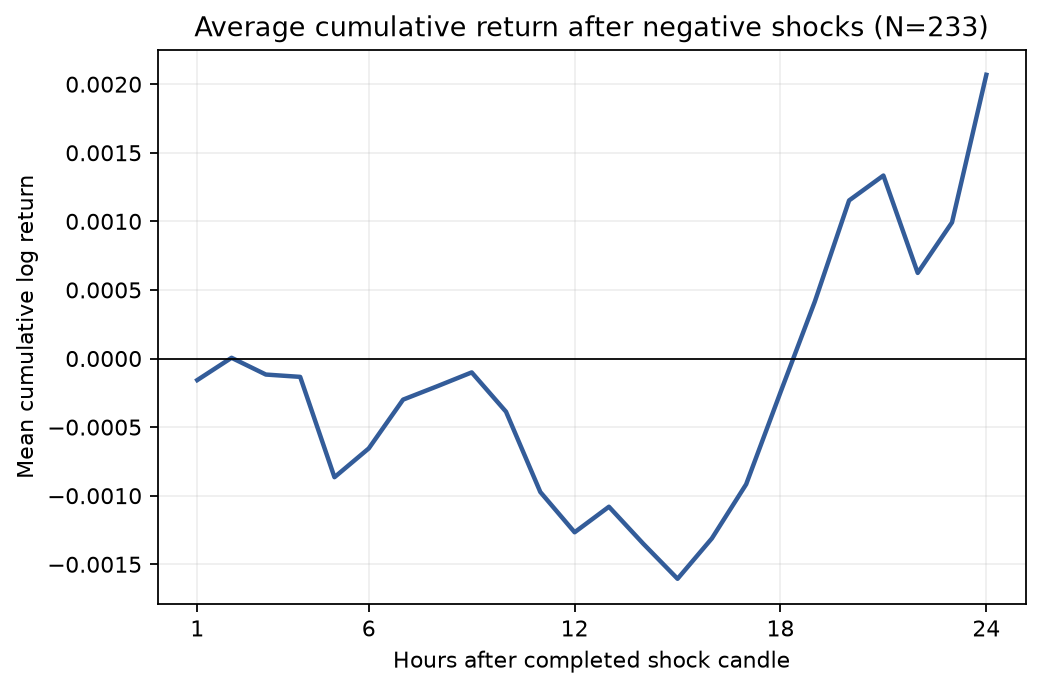

**Historical held out (2024–July 2026)**

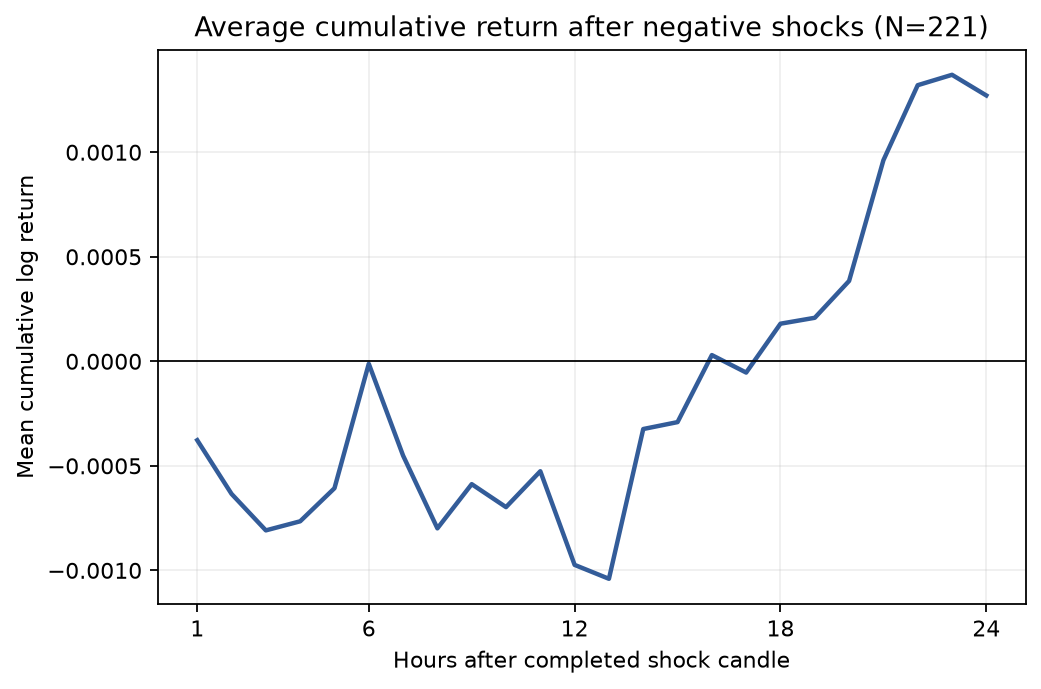

In [13]:
display(Markdown('**Development (2020–2023)**'))
show_png(RUNS['development_inference'] / 'development_average_path.png')
display(Markdown('**Historical held out (2024–July 2026)**'))
show_png(RUNS['held_out'] / 'held_out_average_path.png')

## 4. Backtest

Each strategy buys at the open of the bar after a negative shock and sells at the close of the twelfth bar after the shock bar. Only one position can be open at a time, using all capital; there is no shorting, leverage, stop-loss, or parameter search. The four fixed variants trade all shocks, weekend shocks, low-activity shocks, and shocks that are both. The table uses the primary cost assumption. Portfolio wealth compounds arithmetic net trade returns; the event-study outcome is a log return starting at the shock close, so the two measures have different entry points.

Sharpe uses daily marked-to-market returns, including cash days, annualised with 365 days and a zero risk-free rate. The recorded daily series samples midnight equity after any new entry; a midnight entry cost is assigned to the preceding day. This boundary convention can slightly change Sharpe relative to a mark immediately before entry. Maximum drawdown uses hourly net equity. Annualised Sharpe is descriptive and highly unstable for sparse strategies, particularly the combined rule.

The cell rebuilds the development backtest; the held-out backtest was rebuilt in Section 3.

In [14]:
check_replay(replay.replay_development_backtest)

development_strategy = read_csv(RUNS['development_backtest'] / 'development_strategy_metrics.csv').assign(Split='Development')
held_out_strategy = read_csv(RUNS['held_out'] / 'held_out_strategy_metrics.csv').assign(Split='Held out')
strategy = pd.concat([development_strategy, held_out_strategy], ignore_index=True)
strategy_names = ['all_shock', 'weekend', 'low_activity', 'combined']
primary_strategy = strategy[(strategy['cost_scenario'] == 'primary') & strategy['strategy_name'].isin(strategy_names)].copy()
primary_strategy['Strategy'] = primary_strategy['strategy_name'].str.replace('_', ' ', regex=False)
primary_strategy['Gross return'] = primary_strategy['gross_cumulative_return'].map(lambda value: f'{value:.2%}')
primary_strategy['Net return'] = primary_strategy['net_cumulative_return'].map(lambda value: f'{value:.2%}')
primary_strategy['Sharpe'] = primary_strategy['sharpe_ratio'].map(lambda value: f'{value:.3f}')
primary_strategy['Maximum drawdown'] = primary_strategy['maximum_drawdown'].map(lambda value: f'{value:.2%}')
display(primary_strategy[['Split', 'Strategy', 'trade_count', 'Gross return', 'Net return', 'Sharpe', 'Maximum drawdown']].rename(columns={'trade_count': 'Trades'}).sort_values(['Strategy', 'Split']))

development_benchmarks = read_csv(RUNS['development_backtest'] / 'development_benchmarks.csv').assign(Split='Development')
held_out_benchmarks = read_csv(RUNS['held_out'] / 'held_out_benchmarks.csv').assign(Split='Held out')
benchmarks = pd.concat([development_benchmarks, held_out_benchmarks], ignore_index=True)
btc = benchmarks[(benchmarks['benchmark_name'] == 'btc_buy_and_hold') & (benchmarks['cost_scenario'] == 'primary')].copy()
btc['Net return'] = btc['net_cumulative_return'].map(lambda value: f'{value:.2%}')
display(Markdown('Bitcoin buy-and-hold is shown only as context; its near-continuous exposure is not risk-matched to the sparse event strategies.'))
display(btc[['Split', 'Net return', 'exposure_note']].rename(columns={'exposure_note': 'Exposure note'}))

Development backtest: 8 of 8 rebuilt files match the saved run (2.8 s)


,Split,Strategy,Trades,Gross return,Net return,Sharpe,Maximum drawdown
1,Development,all shock,233,-25.58%,-57.47%,-0.957,-65.31%
16,Held out,all shock,221,-19.37%,-52.57%,-1.328,-57.10%
10,Development,combined,6,-8.79%,-10.10%,-0.697,-10.52%
25,Held out,combined,15,-4.65%,-8.02%,-0.586,-11.86%
7,Development,low activity,25,-0.58%,-6.37%,-0.302,-12.61%
22,Held out,low activity,64,2.72%,-11.91%,-0.497,-19.14%
4,Development,weekend,34,10.54%,1.88%,0.100,-14.34%
19,Held out,weekend,27,-5.83%,-11.74%,-0.435,-19.74%


Bitcoin buy-and-hold is shown only as context; its near-continuous exposure is not risk-matched to the sparse event strategies.

,Split,Net return,Exposure note
2,Development,486.25%,different_exposure_not_risk_matched
6,Held out,48.37%,different_exposure_not_risk_matched


### Transaction costs

The low, primary, and high cost cases were fixed before any outcome was seen. Showing all three makes it clear if a strategy only works with the cheapest costs.

In [15]:
cost_cases = [
    (name, f'{cfg.costs.scenarios[name].fee_per_side * 1e4:g} bp fee + {cfg.costs.scenarios[name].slippage_per_side * 1e4:g} bp slippage')
    for name in ('low', 'primary', 'high')
]
display(pd.DataFrame(cost_cases, columns=['Cost case', 'Per side']))
cost_table = strategy[strategy['strategy_name'].isin(strategy_names + ['weekday_shock'])].pivot_table(
    index=['Split', 'strategy_name', 'trade_count'], columns='cost_scenario',
    values='net_cumulative_return', aggfunc='first',
)[['low', 'primary', 'high']].map(lambda value: f'{value:.2%}').reset_index()
cost_table.columns = ['Split', 'Strategy', 'Trades', 'Low-cost net', 'Primary-cost net', 'High-cost net']
cost_table['Strategy'] = cost_table['Strategy'].str.replace('_', ' ', regex=False)
display(cost_table)

,Cost case,Per side
0,low,5 bp fee + 1 bp slippage
1,primary,10 bp fee + 2 bp slippage
2,high,10 bp fee + 10 bp slippage


,Split,Strategy,Trades,Low-cost net,Primary-cost net,High-cost net
0,Development,all shock,233,-43.74%,-57.47%,-70.70%
1,Development,combined,6,-9.45%,-10.10%,-10.96%
2,Development,low activity,25,-3.52%,-6.37%,-10.04%
3,Development,weekday shock,199,-46.98%,-58.25%,-69.64%
4,Development,weekend,34,6.12%,1.88%,-3.52%
5,Held out,all shock,221,-38.15%,-52.57%,-66.70%
6,Held out,combined,15,-6.35%,-8.02%,-10.20%
7,Held out,low activity,64,-4.88%,-11.91%,-20.49%
8,Held out,weekday shock,194,-32.16%,-46.26%,-60.60%
9,Held out,weekend,27,-8.83%,-11.74%,-15.47%


### Equity and drawdown

Gross and net equity lines show how much costs take away; drawdowns show the losses along the way that a single return figure hides.

**Development equity and drawdown**

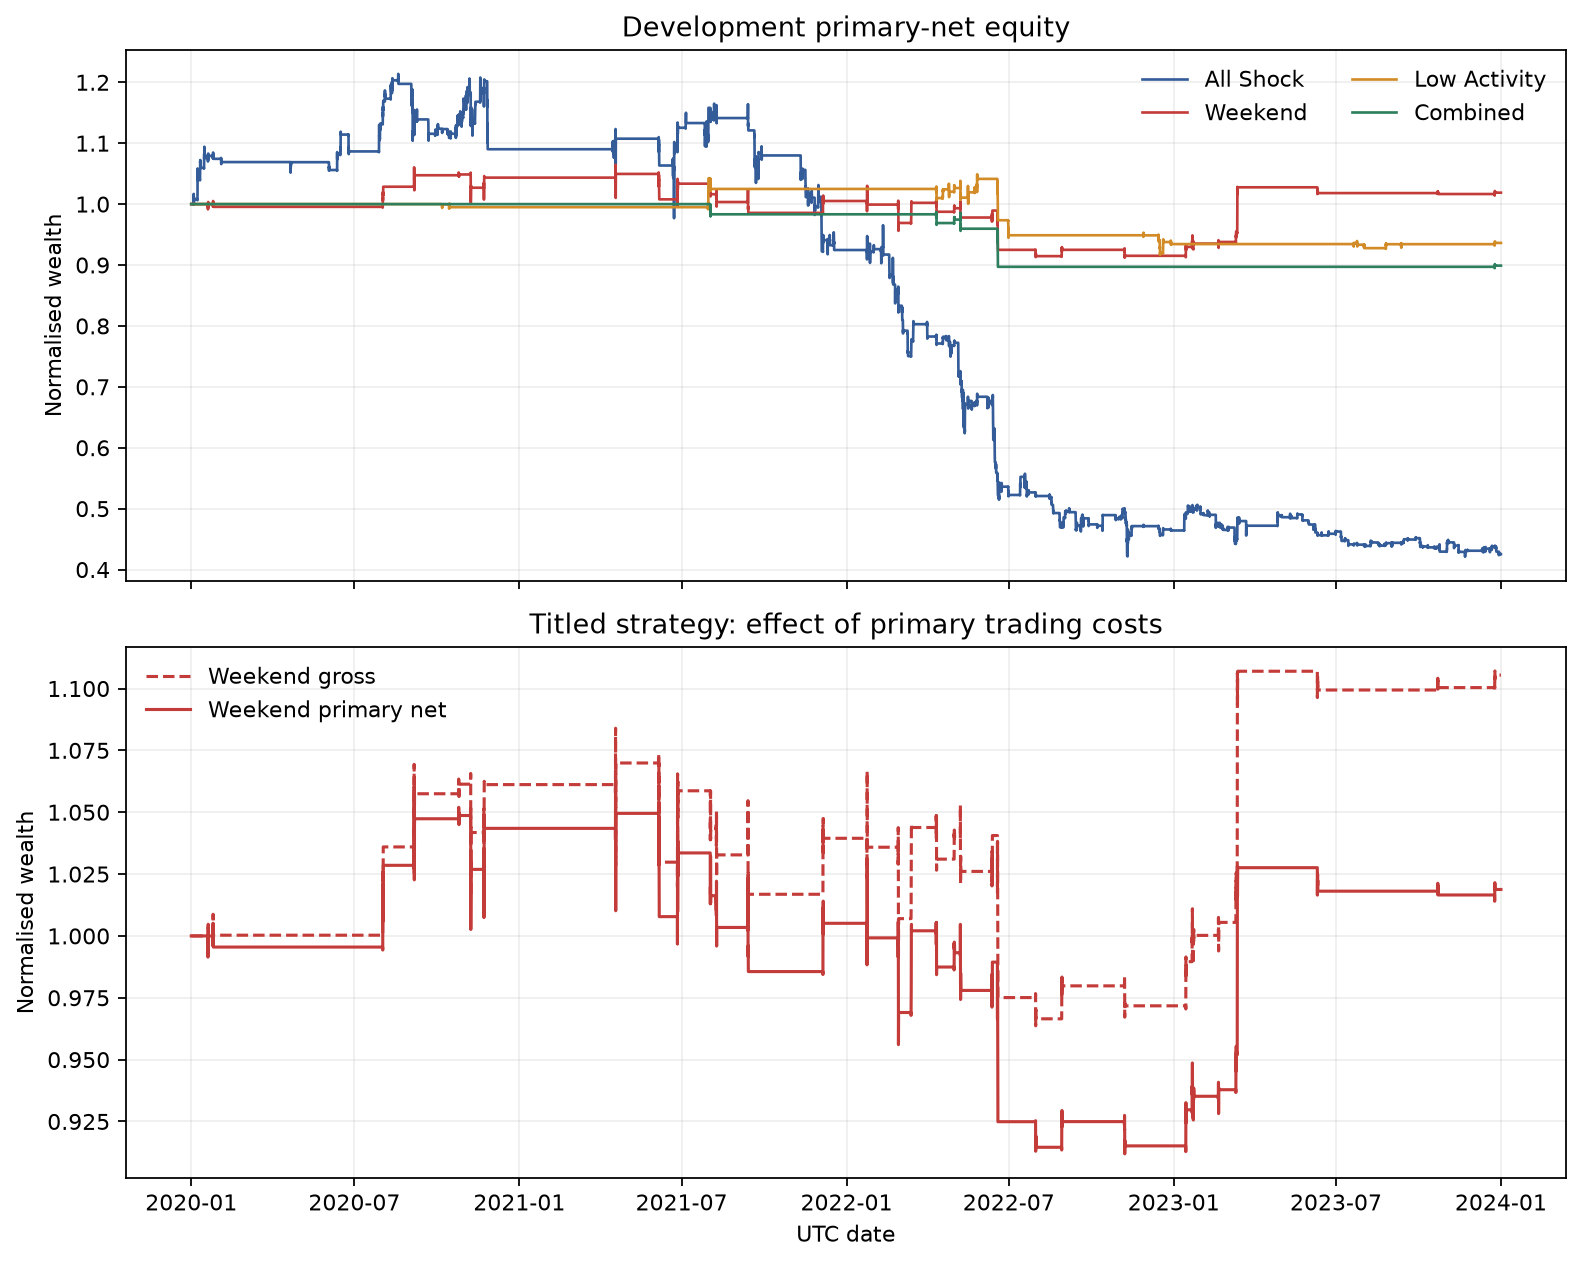

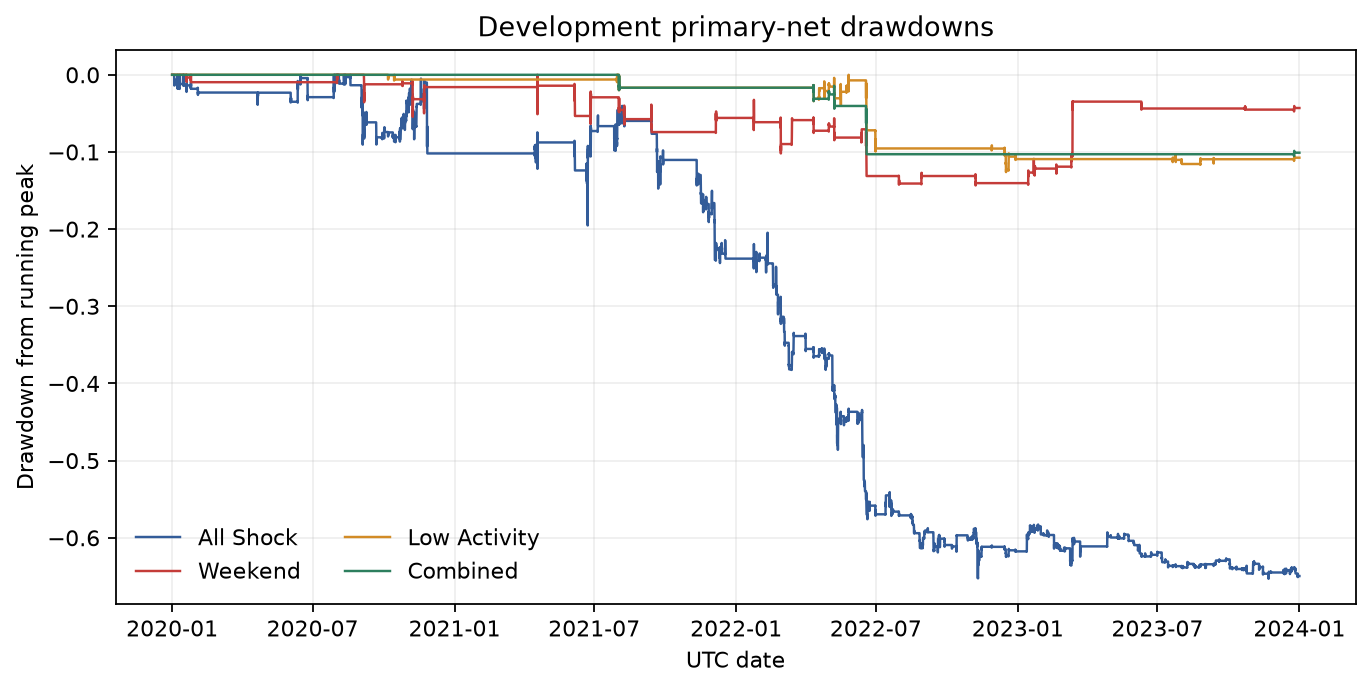

**Historical held-out equity and drawdown**

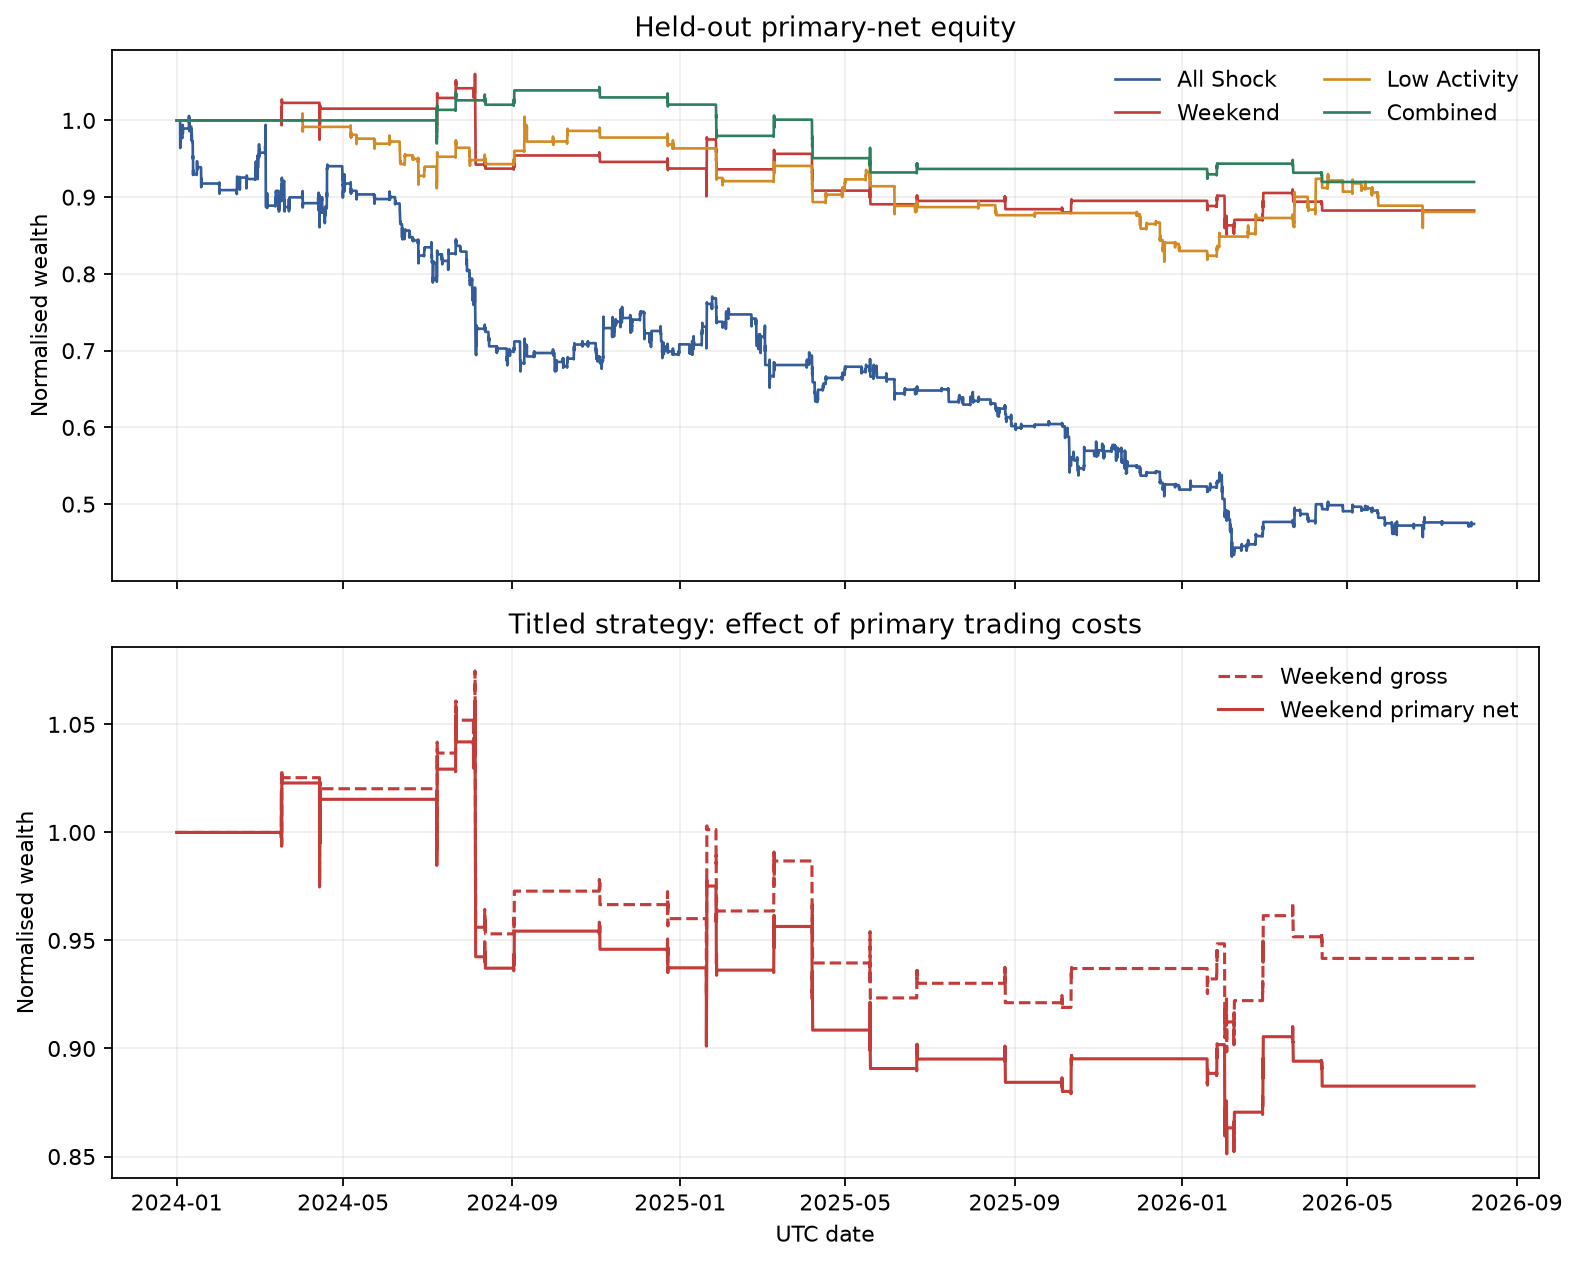

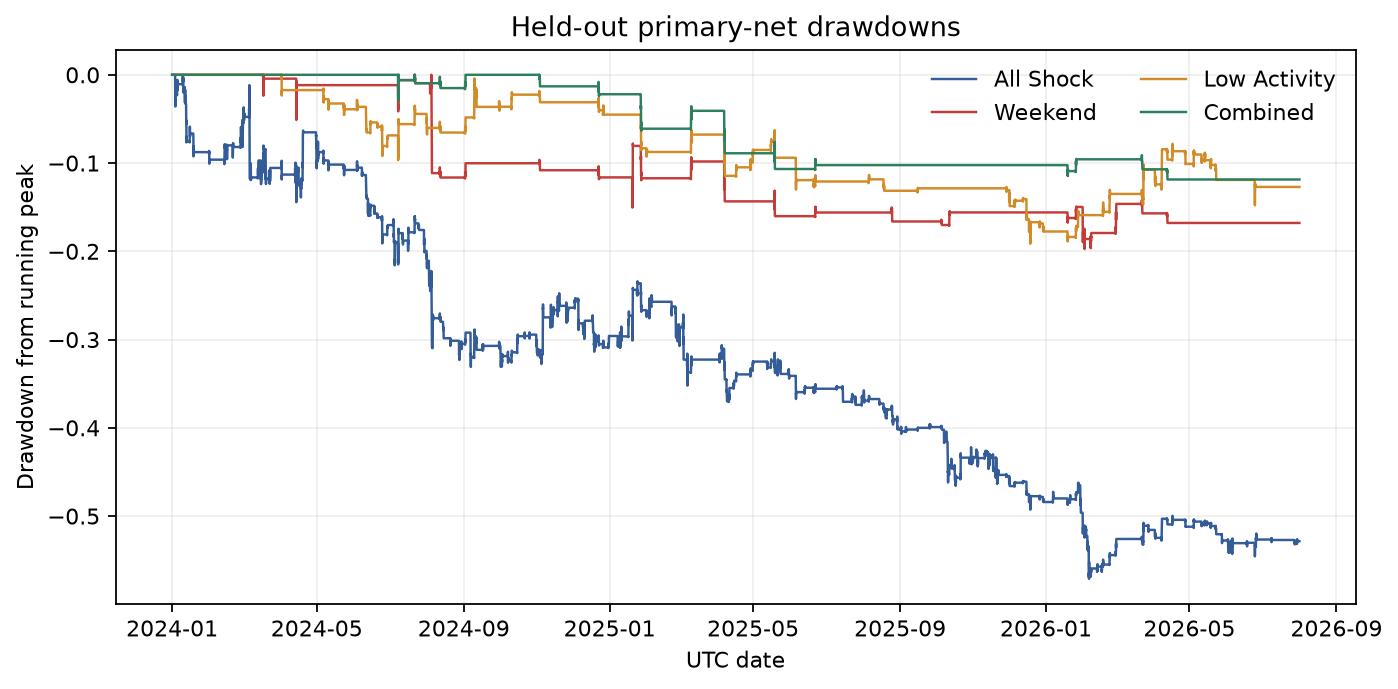

In [16]:
display(Markdown('**Development equity and drawdown**'))
show_png(RUNS['development_backtest'] / 'development_equity_curves.png')
show_png(RUNS['development_backtest'] / 'development_drawdowns.png')
display(Markdown('**Historical held-out equity and drawdown**'))
show_png(RUNS['held_out'] / 'held_out_equity_curves.png')
show_png(RUNS['held_out'] / 'held_out_drawdowns.png')

## 5. Robustness

Each alternative was planned in advance and changes one setting at a time; this is not a search for the best variant. Both robustness runs are rebuilt and their complete family/status counts retained.

The first results table shows all four strategies at thresholds 2.0, 2.5 and 3.0, with primary-cost net returns and trade counts. The next shows the H1 mean and HC3 confidence interval at each threshold. The remaining weekend-rule table shows every recorded strategy alternative and diagnostic, including null and negative results. Deletion diagnostics display ranges; their original return is shown separately and their event identities remain fixed. Calendar-year returns cover individual year slices, rather than the whole split. Costs vary only in the cost rows; other strategy returns use the primary cost.

The locked 2.5 rule remains primary. A positive alternative with few trades is not a validated replacement. Annual stability figures follow the tables.

Development robustness: 2 of 2 rebuilt files match the saved run (3.3 s)
Held-out robustness: 2 of 2 rebuilt files match the saved run (3.2 s)


,Split,family,status,Records
0,Development,activity,complete,6
1,Development,activity,descriptive_highly_unstable,2
2,Development,activity,estimable,8
3,Development,calendar_year,descriptive_year_slice,4
4,Development,calendar_year,estimable,14
5,Development,calendar_year,unestimable,2
6,Development,cooldown,complete,9
7,Development,cooldown,descriptive_highly_unstable,3
8,Development,cooldown,estimable,12
9,Development,cost,verified_stage8_evidence,12


**Threshold sensitivity: all four strategies, primary costs**

,Split,Threshold,Setting,Strategy,Trades,Net return,Status
0,Development,-3.0,Sensitivity,all shock,165,-36.44%,complete
1,Held out,-3.0,Sensitivity,all shock,163,-55.05%,complete
2,Development,-3.0,Sensitivity,combined,3,-7.41%,descriptive highly unstable
3,Held out,-3.0,Sensitivity,combined,7,-5.43%,descriptive highly unstable
4,Development,-3.0,Sensitivity,low activity,16,-13.45%,descriptive highly unstable
5,Held out,-3.0,Sensitivity,low activity,35,-11.15%,complete
6,Development,-3.0,Sensitivity,weekend,20,6.91%,complete
7,Held out,-3.0,Sensitivity,weekend,16,1.38%,descriptive highly unstable
8,Development,-2.5,Primary,all shock,233,-57.47%,complete
9,Held out,-2.5,Primary,all shock,221,-52.57%,complete


**H1 threshold sensitivity: effect sizes and uncertainty**

,Split,Threshold,Events,Mean 12-hour log return,HC3 95% CI
0,Development,-3.0,165,-0.035%,"[-0.501%, 0.432%]"
1,Held out,-3.0,163,-0.250%,"[-0.611%, 0.110%]"
2,Development,-2.5,233,-0.127%,"[-0.467%, 0.214%]"
3,Held out,-2.5,221,-0.097%,"[-0.383%, 0.188%]"
4,Development,-2.0,335,-0.003%,"[-0.282%, 0.276%]"
5,Held out,-2.0,320,-0.017%,"[-0.237%, 0.204%]"


**Remaining weekend strategy alternatives and diagnostics**

,Split,Family,Variant,Trades,Net return,Range after deletion
0,Development,activity,quote volume,34,1.88%,
1,Held out,activity,quote volume,27,-11.74%,
2,Development,activity,trade count,34,1.88%,
3,Held out,activity,trade count,27,-11.74%,
4,Development,calendar year,2020,7,4.35%,
5,Development,calendar year,2021,7,-3.68%,
6,Development,calendar year,2022,11,-8.95%,
7,Development,calendar year,2023,9,11.32%,
8,Held out,calendar year,2024,10,-6.27%,
9,Held out,calendar year,2025,9,-4.49%,


For deletion diagnostics, Net return is the unchanged primary result; the range shows returns after each deletion. n/r means not reported.

**Development calendar-year stability**

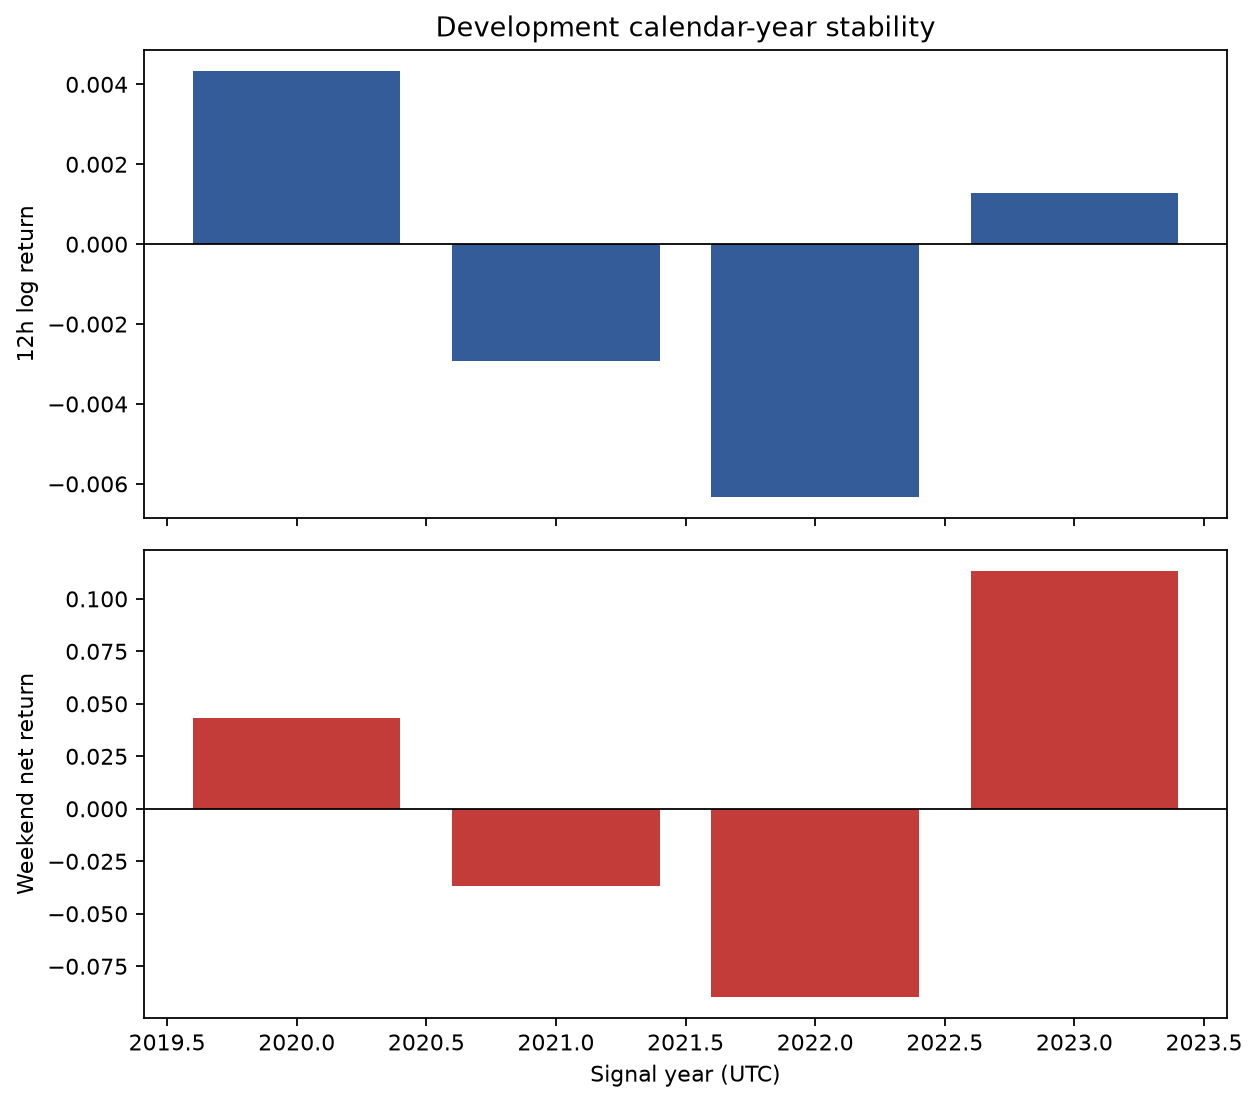

**Historical held-out calendar-year stability**

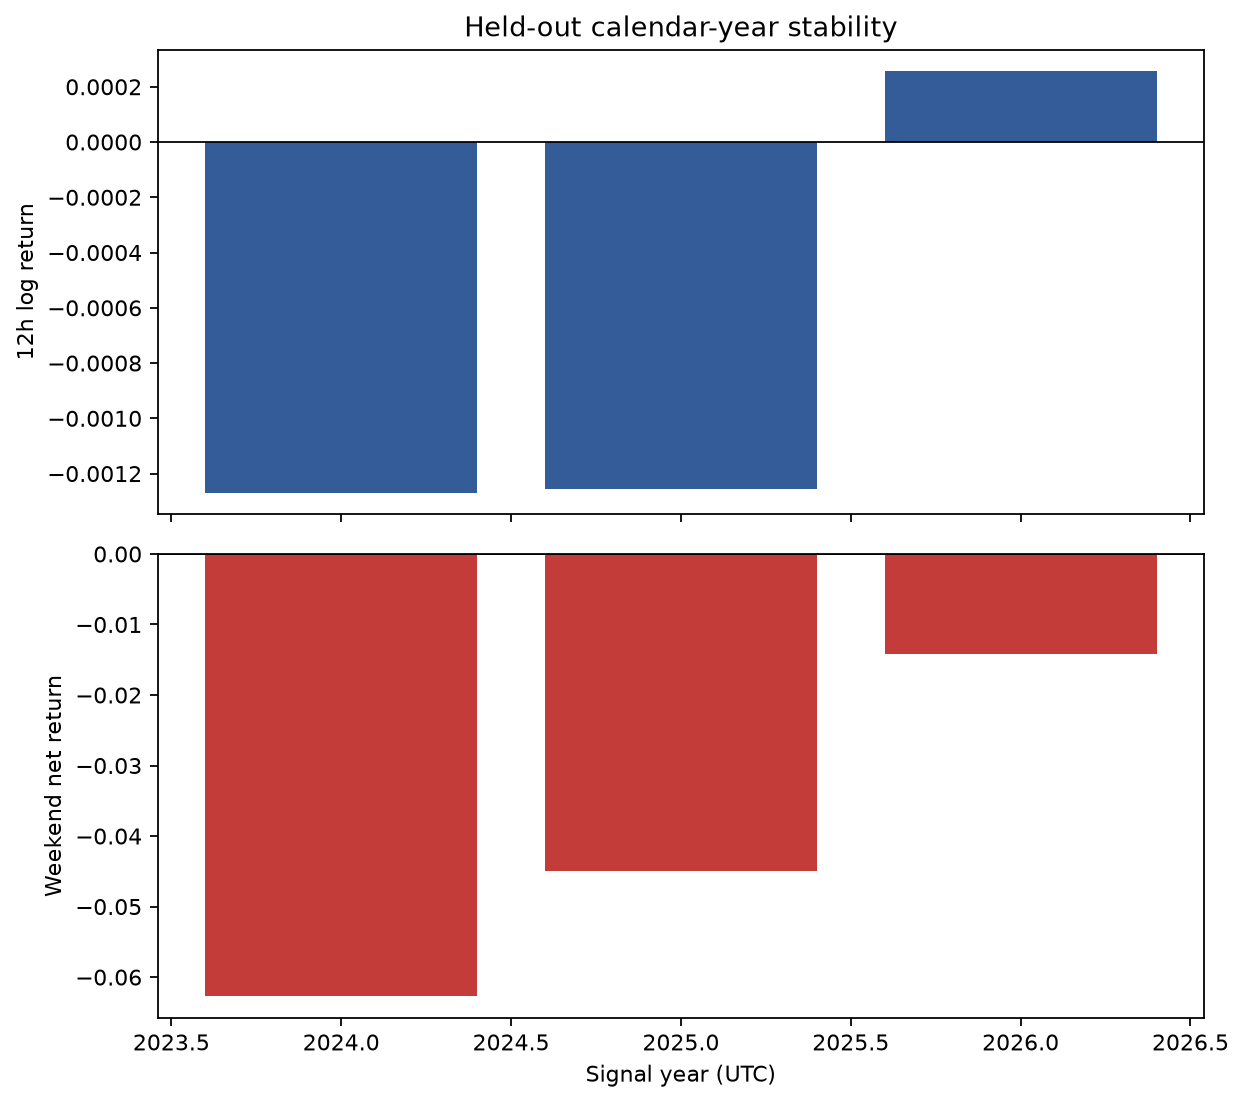

In [17]:
check_replay(replay.replay_development_robustness)
check_replay(replay.replay_held_out_robustness)

development_robustness = read_csv(RUNS['development_robustness'] / 'development_robustness_results.csv').assign(Split='Development')
held_out_robustness = read_csv(RUNS['held_out_robustness'] / 'held_out_robustness_results.csv').assign(Split='Held out')
robustness = pd.concat([development_robustness, held_out_robustness], ignore_index=True)
robustness_summary = robustness.groupby(['Split', 'family', 'status'], dropna=False).size().rename('Records').reset_index()
display(robustness_summary)

threshold_results = robustness[
    (robustness['family'] == 'threshold') & (robustness['analysis'] == 'strategy')
    & (robustness['metric'] == 'primary_net_cumulative_return')
    & robustness['strategy'].isin(strategy_names)
].copy()
if len(threshold_results) != 2 * 3 * len(strategy_names) or threshold_results.duplicated(['Split', 'variant', 'strategy']).any():
    raise ValueError('expected one threshold result per split, cutoff and primary strategy')
threshold_results['Threshold'] = threshold_results['variant'].astype(float)
threshold_results['Setting'] = threshold_results['Threshold'].map(
    lambda value: 'Primary' if value == cfg.shock.negative_threshold else 'Sensitivity'
)
threshold_results['Strategy'] = threshold_results['strategy'].str.replace('_', ' ', regex=False)
threshold_results['Trades'] = threshold_results['trade_count'].astype(int)
threshold_results['Net return'] = threshold_results['estimate'].map(lambda value: f'{value:.2%}')
threshold_results['Status'] = threshold_results['status'].str.replace('_', ' ', regex=False)
display(Markdown('**Threshold sensitivity: all four strategies, primary costs**'))
display(threshold_results[['Split', 'Threshold', 'Setting', 'Strategy', 'Trades', 'Net return', 'Status']]
        .sort_values(['Threshold', 'Strategy', 'Split']).reset_index(drop=True))

threshold_h1 = robustness[
    (robustness['family'] == 'threshold') & (robustness['analysis'] == 'inference')
    & (robustness['model'] == 'model0') & (robustness['term'] == 'intercept')
    & (robustness['metric'] == 'coefficient')
].copy()
if len(threshold_h1) != 6 or threshold_h1.duplicated(['Split', 'variant']).any():
    raise ValueError('expected one H1 estimate per split and cutoff')
threshold_h1['Threshold'] = threshold_h1['variant'].astype(float)
threshold_h1['Events'] = threshold_h1['sample_n'].astype(int)
threshold_h1['Mean 12-hour log return'] = threshold_h1['estimate'].map(lambda value: f'{value:.3%}')
threshold_h1['HC3 95% CI'] = threshold_h1.apply(
    lambda row: f"[{row['range_low']:.3%}, {row['range_high']:.3%}]", axis=1
)
display(Markdown('**H1 threshold sensitivity: effect sizes and uncertainty**'))
display(threshold_h1[['Split', 'Threshold', 'Events', 'Mean 12-hour log return', 'HC3 95% CI']]
        .sort_values(['Threshold', 'Split']).reset_index(drop=True))

weekend_alternatives = robustness[
    (robustness['analysis'] == 'strategy') & (robustness['strategy'] == 'weekend')
    & (robustness['family'] != 'threshold')
].copy()
weekend_alternatives['Family'] = weekend_alternatives['family'].str.replace('_', ' ', regex=False)
weekend_alternatives['Variant'] = weekend_alternatives['variant'].str.replace('_', ' ', regex=False)
weekend_alternatives['Trades'] = weekend_alternatives['trade_count'].map(
    lambda value: str(int(value)) if pd.notna(value) else 'n/r'
)
weekend_alternatives['Net return'] = weekend_alternatives['estimate'].map(lambda value: f'{value:.2%}')
weekend_alternatives['Range after deletion'] = weekend_alternatives.apply(
    lambda row: f"[{row['range_low']:.2%}, {row['range_high']:.2%}]" if pd.notna(row['range_low']) else '', axis=1
)
display(Markdown('**Remaining weekend strategy alternatives and diagnostics**'))
with pd.option_context('display.max_rows', None):
    display(weekend_alternatives[['Split', 'Family', 'Variant', 'Trades', 'Net return', 'Range after deletion']]
            .sort_values(['Family', 'Variant', 'Split']).reset_index(drop=True))
display(Markdown('For deletion diagnostics, Net return is the unchanged primary result; the range shows returns after each deletion. n/r means not reported.'))
display(Markdown('**Development calendar-year stability**'))
show_png(RUNS['development_robustness'] / 'development_calendar_year_stability.png')
display(Markdown('**Historical held-out calendar-year stability**'))
show_png(RUNS['held_out_robustness'] / 'held_out_calendar_year_stability.png')

## 6. Reproducibility and conclusion

The table lists every rebuilt stage. The summary below it is computed from the saved model, strategy, and benchmark tables.

In [18]:
if sorted(f.__name__ for f in replayed_stages) != sorted(f.__name__ for f in STAGE_REPLAYS):
    raise AssertionError('every stage must be rebuilt exactly once')
replay_table = pd.DataFrame({
    'Stage': [result.stage for result in replays],
    'Saved run': [result.accepted_run for result in replays],
    'Files compared': [len(result.comparisons) for result in replays],
    'Identical': [sum(item.matches for item in result.comparisons) for result in replays],
    'Seconds': [round(result.seconds, 1) for result in replays],
})
display(replay_table)
print(f"{replay_table['Identical'].sum()} of {replay_table['Files compared'].sum()} rebuilt files are byte-identical "
      f"to the saved runs; total rebuild time {replay_table['Seconds'].sum():.0f} seconds.")

held_hypotheses = hypotheses[(hypotheses['Split'] == 'Held out') & hypotheses['hypothesis'].isin(primary_hypotheses)]
h5_row = hypotheses[(hypotheses['Split'] == 'Held out') & (hypotheses['hypothesis'] == 'H5')].iloc[0]
unsupported = held_hypotheses['interpretation'].str.contains('not_supported|not_statistically', regex=True).sum()
weekend_row = primary_strategy[(primary_strategy['Split'] == 'Held out') & (primary_strategy['strategy_name'] == 'weekend')].iloc[0]
low_activity_row = primary_strategy[(primary_strategy['Split'] == 'Held out') & (primary_strategy['strategy_name'] == 'low_activity')].iloc[0]
btc_row = btc[btc['Split'] == 'Held out'].iloc[0]
display(Markdown(
    f"""
- **Reproducibility:** all {replay_table['Files compared'].sum()} rebuilt files across {len(replay_table)} stages are identical to the saved runs.
- **Confirmatory H1-H4:** {unsupported} of {len(held_hypotheses)} hypotheses were unsupported in the historical held-out period.
- **Secondary H5:** the positive-minus-negative shock coefficient is {h5_row['estimate']:.3%}, with HC3 95% CI [{h5_row['ci_95_low']:.3%}, {h5_row['ci_95_high']:.3%}] and two-sided p = {h5_row['raw_p_value']:.4f}. H5 is outside the Holm family; its HC3 and month-block intervals are shown in the secondary table.
- **Weekend strategy:** {int(weekend_row['trade_count'])} held-out trades produced {weekend_row['net_cumulative_return']:.2%} net, with Sharpe {weekend_row['sharpe_ratio']:.3f} and maximum drawdown {weekend_row['maximum_drawdown']:.2%}.
- **Activity result:** the held-out low-activity strategy was {low_activity_row['gross_cumulative_return']:.2%} gross but {low_activity_row['net_cumulative_return']:.2%} net, showing that the small gross edge did not survive stated costs.
- **Market context:** BTC buy-and-hold returned {btc_row['net_cumulative_return']:.2%} net over the held-out interval, but it is not a risk-matched benchmark.

**Conclusion:** for the market, dates, signal, trade timing, and costs tested here, there is no reliable evidence that buying the weekend dip gave a stable or profitable edge. The held-out period is historical, so this is a pseudo-out-of-sample test rather than live trading evidence, and it does not show causation.
"""
))

,Stage,Saved run,Files compared,Identical,Seconds
0,Cleaning,20260904T150910.352311Z-validate-2114d1d3-82e4cb,8,8,4.6
1,Features,20260906T003831.725064Z-features-92e5ff02-878985,1,1,6.2
2,Count check,20260906T011026.732695Z-count-only-5b9fb859-11...,1,1,1.7
3,Development outcomes,20260907T231307.800702Z-development-5b472caa-3...,3,3,1.9
4,Development models,20260908T152939.777879Z-development-0f73422e-0...,10,10,30.1
5,Held-out evaluation,20260910T133543.269946Z-held-out-dad36cad-632a5e,21,21,37.9
6,Development backtest,20260908T165150.697815Z-backtest-509b876c-aa730c,8,8,2.8
7,Development robustness,20260909T104454.475358Z-robustness-e052ad2d-dc...,2,2,3.3
8,Held-out robustness,20260910T144404.535764Z-held-out-robustness-de...,2,2,3.2


56 of 56 rebuilt files are byte-identical to the saved runs; total rebuild time 92 seconds.



- **Reproducibility:** all 56 rebuilt files across 9 stages are identical to the saved runs.
- **Confirmatory H1-H4:** 4 of 4 hypotheses were unsupported in the historical held-out period.
- **Secondary H5:** the positive-minus-negative shock coefficient is 0.286%, with HC3 95% CI [-0.126%, 0.697%] and two-sided p = 0.1735. H5 is outside the Holm family; its HC3 and month-block intervals are shown in the secondary table.
- **Weekend strategy:** 27 held-out trades produced -11.74% net, with Sharpe -0.435 and maximum drawdown -19.74%.
- **Activity result:** the held-out low-activity strategy was 2.72% gross but -11.91% net, showing that the small gross edge did not survive stated costs.
- **Market context:** BTC buy-and-hold returned 48.37% net over the held-out interval, but it is not a risk-matched benchmark.

**Conclusion:** for the market, dates, signal, trade timing, and costs tested here, there is no reliable evidence that buying the weekend dip gave a stable or profitable edge. The held-out period is historical, so this is a pseudo-out-of-sample test rather than live trading evidence, and it does not show causation.
